# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [1]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [2]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [3]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [5]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [6]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [7]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

In [8]:
print(data[['sex','sex_label']].drop_duplicates())
print()
print(data[['embarked'] + [c for c in data.columns if c.startswith('embarked_')]].drop_duplicates())

      sex  sex_label
0    male          1
1  female          0

   embarked  embarked_C  embarked_Q  embarked_S
0         S       False       False        True
1         C        True       False       False
5         Q       False        True       False
61      NaN       False       False       False


**Respuesta:** LabelEncoder convierte cada categoría en un número entero dentro de una sola columna (female=0, male=1). OneHotEncoder crea una columna binaria por categoría (embarked_C, embarked_Q, embarked_S). LabelEncoder introduce un orden artificial (2 > 1 > 0) que el modelo puede malinterpretar; One-Hot evita ese orden a cambio de crear más columnas.

Nota: los 2 pasajeros sin puerto de embarque (`embarked` = NaN) quedan con las tres columnas en False. `pd.get_dummies` ignora los faltantes por defecto; con `dummy_na=True` se crearía una columna `embarked_nan` para identificarlos.

In [9]:
print("Filas con embarked faltante:", data['embarked'].isnull().sum())
print(pd.get_dummies(data['embarked'], prefix='embarked', dummy_na=True).loc[data['embarked'].isnull()])

Filas con embarked faltante: 2
     embarked_C  embarked_Q  embarked_S  embarked_nan
61        False       False       False          True
829       False       False       False          True


### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

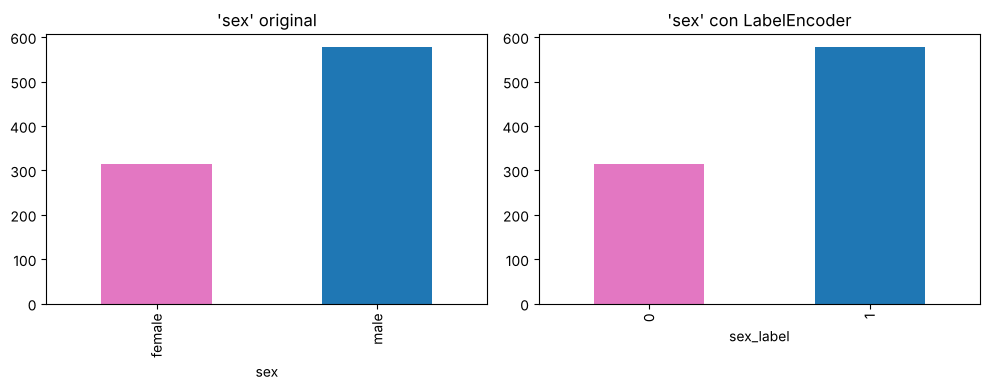

In [10]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
data['sex'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color=['tab:pink','tab:blue'])
axes[0].set_title("'sex' original")
data['sex_label'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color=['tab:pink','tab:blue'])
axes[1].set_title("'sex' con LabelEncoder")
plt.tight_layout(); plt.show()

**Respuesta:** las frecuencias son idénticas (314 mujeres y 577 hombres); la codificación solo cambia la etiqueta (female→0, male→1), sin alterar la información.

### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [11]:
ohe = OneHotEncoder(sparse_output=False)
class_ohe = pd.DataFrame(ohe.fit_transform(data[['class']]),
                         columns=ohe.get_feature_names_out(['class']), index=data.index)
data = pd.concat([data, class_ohe], axis=1)
data[['class'] + list(class_ohe.columns)].head()

,class,class_First,class_Second,class_Third
0,Third,0.0,0.0,1.0
1,First,1.0,0.0,0.0
2,Third,0.0,0.0,1.0
3,First,1.0,0.0,0.0
4,Third,0.0,0.0,1.0


**Respuesta:** con LabelEncoder, First/Second/Third quedarían como números y el modelo asumiría distancias iguales entre clases (y el orden alfabético no coincide con el real). One-Hot trata cada clase como independiente, sin suponer relaciones numéricas, y `OneHotEncoder` de sklearn recuerda las categorías para aplicarlas igual a datos nuevos dentro de un pipeline.

### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

In [12]:
print(data[categorical_cols].nunique())

sex         2
embarked    3
class       3
dtype: int64


In [13]:
from sklearn.preprocessing import OrdinalEncoder
ord_enc = OrdinalEncoder(categories=[['Third', 'Second', 'First']])
data['class_ordinal'] = ord_enc.fit_transform(data[['class']])
print(data[['class', 'class_ordinal']].drop_duplicates().sort_values('class_ordinal'))
print("\nTasa de supervivencia por nivel ordinal:")
print(data.groupby('class_ordinal')['survived'].mean())

    class  class_ordinal
0   Third            0.0
9  Second            1.0
1   First            2.0

Tasa de supervivencia por nivel ordinal:
class_ordinal
0.0    0.242363
1.0    0.472826
2.0    0.629630
Name: survived, dtype: float64


**Respuesta:** para variables **nominales** sin orden (sex, embarked) usaría One-Hot, sobre todo con modelos lineales, KNN o redes, que interpretan los números como magnitudes. Para variables **ordinales** como class (Primera > Segunda > Tercera) puede usarse una codificación ordinal que respete ese orden real. LabelEncoder lo dejaría para la variable objetivo o para modelos de árboles, que son menos sensibles al orden artificial. Si una variable tiene muchísimas categorías, conviene agruparlas o usar otras técnicas para no disparar el número de columnas.